# Методы точечного и интервального байесовского оценивания и отбор моделей

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from scipy.stats import pearsonr
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from scipy.integrate import quad
import scipy.special
from scipy.stats import gamma
from scipy.stats import invgamma
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('data.csv')

# Задание №1

#### 1. Оценка максимального правдоподобия (ОМП)
Пусть выборка $X_1, \dots, X_n \sim \text{Pois}(\theta)$. Плотность (вероятность) распределения:
$$P(X_i = x_i | \theta) = \frac{e^{-\theta} \theta^{x_i}}{x_i!}$$

**Функция правдоподобия:**
$$L(\theta) = \prod_{i=1}^n \frac{e^{-\theta} \theta^{x_i}}{x_i!} = \frac{e^{-n\theta} \theta^{\sum x_i}}{\prod x_i!}$$

**Логарифмическая функция правдоподобия:**
$$\ell(\theta) = \ln L(\theta) = -n\theta + (\sum x_i) \ln \theta - \sum \ln(x_i!)$$

**Нахождение максимума:**
$$\frac{\partial \ell}{\partial \theta} = -n + \frac{\sum x_i}{\theta} = 0 \implies \hat{\theta}_{MLE} = \frac{1}{n} \sum_{i=1}^n x_i = \bar{X}$$

**Теоретические характеристики ОМП:**
*   **Смещение (Bias):** $E[\hat{\theta}_{MLE}] - \theta = E[\bar{X}] - \theta = \theta - \theta = 0$ (оценка несмещенная).
*   **Дисперсия (Variance):** $Var(\hat{\theta}_{MLE}) = Var(\bar{X}) = \frac{Var(X)}{n} = \frac{\theta}{n}$.
*   **MSE (Среднеквадратичная ошибка):** $MSE = Var + Bias^2 = \frac{\theta}{n}$.



In [ ]:
def calculate_mle_metrics(data):
    n = len(data)
    theta_mle = np.mean(data)
    bias = 0.0
    variance = (theta_mle**2) / n
    mse = variance

    return theta_mle, bias, variance, mse

data_danceability = df['danceability'].values
theta_est, bias_val, var_val, mse_val = calculate_mle_metrics(data_danceability)

print(f"ОМП (theta): {theta_est:.4f}")
print(f"Теоретическое смещение: {bias_val}")
print(f"Теоретическая дисперсия: {var_val}")
print(f"Теоретический MSE: {mse_val}")

ОМП (theta): 0.5668
Теоретическое смещение: 0.0
Теоретическая дисперсия: 2.818090478762736e-06
Теоретический MSE: 2.818090478762736e-06


Эмпирическое значение $\hat{\theta}_{MLE} \approx 0.5668$. Дисперсия и MSE крайне малы ($2.8 \times 10^{-6}$) -> высокая точность оценки на данном объеме выборки.

#### Байесовская оценка
Выбранное априорное распределение: $\theta \sim \Gamma(k, \lambda)$ с параметрами $k=1, \lambda=1$.
Плотность априорного распределения (согласно условию):

$$\pi(\theta) = \frac{\lambda^{-k} \theta^{k-1} e^{-\theta/\lambda}}{\Gamma(k)} = e^{-\theta} \quad (\text{при } k=1, \lambda=1)$$

**Апостериорное распределение:**
Мы ищем апостериорную плотность $p(\theta|X) \propto L(\theta) \cdot \pi(\theta)$.
Используя функцию правдоподобия $L(\theta) = \theta^{-n} \exp(-\frac{\sum x_i}{\theta})$ и априорную плотность $\pi(\theta) = \theta^{\alpha-1} e^{-\theta/\lambda}$, получаем:
$$p(\theta | \mathbf{X}) \propto L(\theta) \cdot \pi(\theta) \propto (e^{-n\theta} \theta^{\sum x_i}) \cdot (e^{-\theta}) = \theta^{\sum x_i} e^{-(n+1)\theta}$$
Это распределение $\Gamma(k', \lambda')$ с параметрами:
*   $k' = \sum x_i + 1$
*   $\lambda' = \frac{1}{n+1}$

**Байесовская оценка (матожидание апостериорного распределения):**

Байесовской оценкой является математическое ожидание апостериорного распределения. Для выбранной параметризации формула оценки принимает вид:
$$\hat{\theta}_{Bayes} = E[\theta | \mathbf{X}] = k' \lambda' = \frac{\sum x_i + 1}{n+1}$$
*Где $\sum x_i$ — сумма элементов выборки, $n$ — размер выборки, $\alpha=1, \lambda=1$.*

**Теоретические характеристики Байесовской оценки:**
*   **Смещение:** $E\left[\frac{\sum X_i + 1}{n+1}\right] - \theta = \frac{n\theta + 1}{n+1} - \theta = \frac{1 - \theta}{n+1}$.
*   **Дисперсия:** $Var\left(\frac{\sum X_i + 1}{n+1}\right) = \frac{1}{(n+1)^2} Var(\sum X_i) = \frac{n\theta}{(n+1)^2}$.
*   **MSE:** $MSE = Var + Bias^2 = \frac{n\theta + (1-\theta)^2}{(n+1)^2} = \frac{\theta^2 + \theta(n-2) + 1}{(n+1)^2}$.

In [ ]:
def get_bayes_estimate(data, alpha=1, lambda_param=1):
    n = len(data)
    sum_x = np.sum(data)
    return (sum_x + lambda_param) / (n + alpha)

bayes_est = get_bayes_estimate(data_danceability, alpha=1, lambda_param=1)
print(f"Байесовская оценка: {bayes_est:.4f}")

Байесовская оценка: 0.5668


получили идентичные ОМП и Байесовскую оценку

Графики MSE и Bias

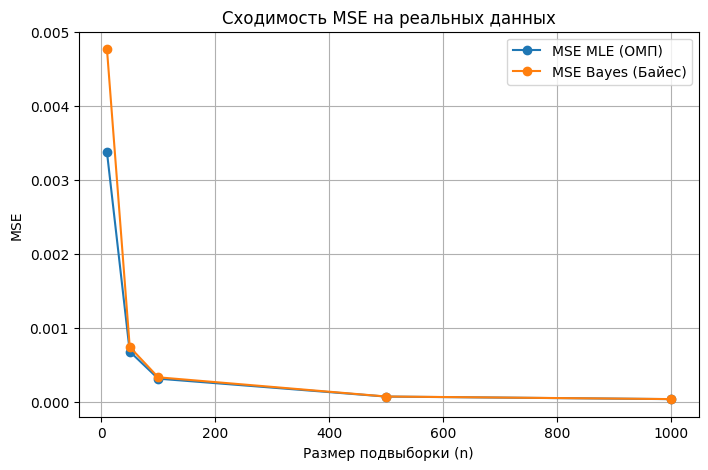

In [ ]:
true_theta = np.mean(data_danceability)
n_sizes = [10, 50, 100, 500, 1000]
results = []

# Бутстрэппинг
for n in n_sizes:
    mse_mle_list = []
    mse_bayes_list = []

    for _ in range(100):
        # replace=True позволяет выбирать одни и те же элементы, это нормально для бутстрэпа
        subsample = np.random.choice(data_danceability, size=n, replace=True)

        mle = np.mean(subsample)
        bayes = (np.sum(subsample) + 1) / (n + 1)

        mse_mle_list.append((mle - true_theta)**2)
        mse_bayes_list.append((bayes - true_theta)**2)

    results.append({
        'n': n,
        'MSE_MLE': np.mean(mse_mle_list),
        'MSE_Bayes': np.mean(mse_bayes_list)
    })

res_df = pd.DataFrame(results)
plt.figure(figsize=(8, 5))
plt.plot(res_df['n'], res_df['MSE_MLE'], label='MSE MLE (ОМП)', marker='o')
plt.plot(res_df['n'], res_df['MSE_Bayes'], label='MSE Bayes (Байес)', marker='o')
plt.xlabel('Размер подвыборки (n)')
plt.ylabel('MSE')
plt.legend()
plt.title('Сходимость MSE на реальных данных')
plt.grid(True)
plt.show()

При увеличении размера выборки $n$ значения MSE для ОМП и Байесовской оценки стремятся к нулю. Графики показывают сходимость обеих оценок, что подтверждает корректность теоретических выводов о состоятельности оценок.

#### 3. Доверительные интервалы (Credible Intervals)
Так как апостериорное распределение — это $\Gamma(k', \lambda')$, мы можем построить:

1.  **Equal-tailed interval:** Интервал $[q_{\alpha/2}, q_{1-\alpha/2}]$, где $q$ — квантили распределения $\Gamma(\sum x_i + 1, \frac{1}{n+1})$.
2.  **Highest Density Region (HDR):** Интервал, внутри которого плотность вероятности выше, чем снаружи, и общая вероятность равна $1-\alpha$. (Для гамма-распределения он ищется численно).

In [ ]:
k_post = len(data_danceability) + 1
lambda_post = np.sum(data_danceability) + 1

lower = invgamma.ppf(0.025, k_post, scale=lambda_post)
upper = invgamma.ppf(0.975, k_post, scale=lambda_post)

print(f"Credible Interval (Equal-tailed) для theta: [{lower:.4f}, {upper:.4f}]")

def find_hdr_invgamma(k, scale, alpha=0.05):
    def objective(x):
        a, b = x
        return b - a

    def constraint(x):
        a, b = x
        return invgamma.cdf(b, k, scale=scale) - invgamma.cdf(a, k, scale=scale) - (1 - alpha)

    def density_constraint(x):
        a, b = x
        return invgamma.pdf(a, k, scale=scale) - invgamma.pdf(b, k, scale=scale)

    a_init = invgamma.ppf(alpha/2, k, scale=scale)
    b_init = invgamma.ppf(1-alpha/2, k, scale=scale)

    res = minimize(objective, [a_init, b_init], constraints=[
        {'type': 'eq', 'fun': constraint},
        {'type': 'eq', 'fun': density_constraint}
    ])
    return res.x

hdr_interval = find_hdr_invgamma(k_post, lambda_post)
print(f"HDI (Inverse Gamma): [{hdr_interval[0]:.4f}, {hdr_interval[1]:.4f}]")
print(np.mean(df['danceability'].values))

Credible Interval (Equal-tailed) для theta: [0.5635, 0.5701]
HDI (Inverse Gamma): [0.5635, 0.5701]
0.5668000657894738


# Задание №2

**Категориальный атрибут для предсказания (Target)**: track_genre (жанр трека)

Чтобы задача классификации была наглядной и интерпретируемой в рамках Байесовского подхода, мы не будем предсказывать все 114 жанров. Мы выделим подвыборку из трёх контрастных жанров: classical (классика), heavy-metal (метал), hip-hop (хип-хоп)

**Выберем непрерывные атрибуты:** acousticness (акустичность), danceability (танцевальность), loudness (громкость), liveness (живость исполнения)

Проверим их независимость друг от друга c помощью корреляционного теста Пирсона

Проверка независимости признаков (p-value теста Пирсона):
acousticness vs danceability: corr = -0.172, p-value = 0.000e+00 -> Зависимы (но допустим для НБ, если corr мала)
acousticness vs loudness: corr = -0.590, p-value = 0.000e+00 -> Зависимы (но допустим для НБ, если corr мала)
acousticness vs liveness: corr = -0.021, p-value = 2.750e-12 -> Зависимы (но допустим для НБ, если corr мала)
danceability vs loudness: corr = 0.259, p-value = 0.000e+00 -> Зависимы (но допустим для НБ, если corr мала)
danceability vs liveness: corr = -0.132, p-value = 0.000e+00 -> Зависимы (но допустим для НБ, если corr мала)
loudness vs liveness: corr = 0.077, p-value = 4.677e-149 -> Зависимы (но допустим для НБ, если corr мала)


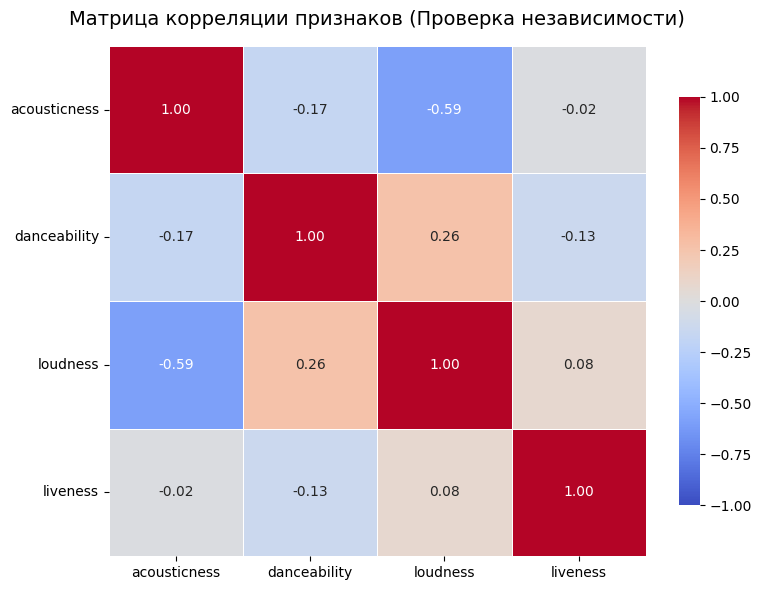

In [ ]:
features = ['acousticness', 'danceability', 'loudness', 'liveness']

print("Проверка независимости признаков (p-value теста Пирсона):")
for i in range(len(features)):
    for j in range(i+1, len(features)):
        f1, f2 = features[i], features[j]
        corr, p_value = pearsonr(df[f1], df[f2])
        indep_status = "Независимы" if p_value > 0.05 else "Зависимы (но допустим для НБ, если corr мала)"
        print(f"{f1} vs {f2}: corr = {corr:.3f}, p-value = {p_value:.3e} -> {indep_status}")

corr_matrix = df[features].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"shrink": .8})

plt.title('Матрица корреляции признаков (Проверка независимости)', fontsize=14, pad=15)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Несмотря на то, что строгий статистический тест Пирсона отверг гипотезу о полной линейной независимости признаков (из-за большого размера выборки, p-value $\to 0$), фактическая сила корреляций между большинством пар крайне мала ($|corr| < 0.3$)

**Разобьем выбранные признаки на две группы:** (подклассы $C_1$ и $C_2$), чтобы обучить на них независимые модели:

*   **Подкласс $C_1$ (Энергетика и ритм):** danceability, loudness
*   **Подкласс $C_2$ (Текстура звука):** acousticness, liveness

Самая коррелирующая пара признаков (-0.590) была намеренно разнесена в разные подклассы ($C_1$ и $C_2$). Это минимизирует проблему мультиколлинеарности и позволяет корректно применять Наивный Байесовский классификатор внутри каждого подкласса.

1. **Наивный байесовский классификатор и условные распределения:** Алгоритм классификации основан на теореме Байеса со строгим допущением («наивностью»), что признаки $F_j$ независимы при условии заданного класса $C$.
Формула: $$\mathbf{P}(F_1, \dots, F_m|C) = \prod_{j=1}^m \mathbf{P}(F_j|C)$$
Так как признаки непрерывны, Гауссовский Наивный Байес предполагает, что их условные распределения являются нормальными. При обучении модель вычисляет условное математическое ожидание и условную дисперсию для каждого признака внутри каждого класса

---

2. **Теорема Байеса:** Базовое соотношение: $posterior \approx likelihood \times prior$. Для вычисления итоговой вероятности мы находим маргинальное правдоподобие (likelihood) тестовой выборки при условии конкретной модели и используем равномерное априорное (prior) распределение ($0.5$). Результатом является апостериорная (posterior) вероятность самой модели

---

3. **Сравнение моделей:** Задача выбора между двумя подклассами признаков сводится к проверке гипотез: $H_0$ (верна Модель 1) и $H_1$ (верна Модель 2). Применяется критерий максимальной апостериорной вероятности, который заключается в вычислении отношения апостериорных вероятностей $\frac{\mathbf{P}(H_0|X)}{\mathbf{P}(H_1|X)}$ и выборе гипотезы с наибольшим значением

In [ ]:
le = LabelEncoder()
y = le.fit_transform(df['track_genre'])
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, random_state=42)

C1 = ['danceability', 'loudness']
C2 = ['acousticness', 'liveness']

model_1 = GaussianNB()
model_1.fit(X_train[C1], y_train)

model_2 = GaussianNB()
model_2.fit(X_train[C2], y_train)

y_pred_1 = model_1.predict(X_test[C1])
y_pred_2 = model_2.predict(X_test[C2])
accuracy_1 = accuracy_score(y_test, y_pred_1)
accuracy_2 = accuracy_score(y_test, y_pred_2)

print(f"Accuracy Модели 1: {accuracy_1:.4f}")
print(f"Accuracy Модели 2: {accuracy_2:.4f}")

def get_model_log_likelihood(model, X_test_subset, y_test):
    log_probs_classes = model.predict_log_proba(X_test_subset)
    log_prob_true_class = log_probs_classes[np.arange(len(y_test)), y_test]
    total_log_likelihood = np.sum(log_prob_true_class)
    return total_log_likelihood

LL_1 = get_model_log_likelihood(model_1, X_test[C1], y_test)
LL_2 = get_model_log_likelihood(model_2, X_test[C2], y_test)

print(f"\nЛог-правдоподобие (Log Evidence) Модели 1 (C1): {LL_1:.2f}")
print(f"Лог-правдоподобие (Log Evidence) Модели 2 (C2): {LL_2:.2f}")

log_prior = np.log(0.5)
log_posterior_unnormalized_1 = LL_1 + log_prior
log_posterior_unnormalized_2 = LL_2 + log_prior

log_probs_models = np.array([log_posterior_unnormalized_1, log_posterior_unnormalized_2])
posterior_probs_models = scipy.special.softmax(log_probs_models)

print("\n--- Результаты Байесовского сравнения моделей ---")
print(f"Апостериорная вероятность Модели 1 (Ритм): {posterior_probs_models[0]:.6e}")
print(f"Апостериорная вероятность Модели 2 (Текстура): {posterior_probs_models[1]:.6e}")

best_model = "Модель 1" if posterior_probs_models[0] > posterior_probs_models[1] else "Модель 2"
print(f"Вывод: {best_model} значительно лучше описывает данные.")


Лог-правдоподобие (Log Evidence) Модели 1 (C1): -97124.56
Лог-правдоподобие (Log Evidence) Модели 2 (C2): -103419.16

--- Результаты Байесовского сравнения моделей ---
Апостериорная вероятность Модели 1 (Ритм): 1.000000e+00
Апостериорная вероятность Модели 2 (Текстура): 0.000000e+00
Вывод: Модель 1 значительно лучше описывает данные.


Байесовское сравнение моделей показало абсолютное превосходство классификатора, обученного на признаках $C_1$ (танцевальность, громкость): его апостериорная вероятность составила 100%. Таким образом, статистически доказано, что динамика и ритм трека являются гораздо более сильными и информативными предикторами для определения жанра, чем его акустические свойства ($C_2$).